In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("/content/cleaned_support_tickets.csv")

In [5]:
df

,flags,utterance,category,intent,text_length,Lower_text,no_html,no_url,no_email,clean_text,tokens,filtered_tokens,lemmatized_tokens,lemmatized_text,processed_text
0,BM,I have problems with canceling an order,ORDER,cancel_order,7,i have problems with canceling an order,i have problems with canceling an order,i have problems with canceling an order,i have problems with canceling an order,i have problems with canceling an order,"['i', 'have', 'problems', 'with', 'canceling',...","['problems', 'canceling', 'order']","['problem', 'cancel', 'order']",problem cancel order,problem cancel order
1,BIM,how can I find information about canceling ord...,ORDER,cancel_order,8,how can i find information about canceling ord...,how can i find information about canceling ord...,how can i find information about canceling ord...,how can i find information about canceling ord...,how can i find information about canceling orders,"['how', 'can', 'i', 'find', 'information', 'ab...","['find', 'information', 'canceling', 'orders']","['find', 'information', 'cancel', 'order']",find information cancel order,find information cancel order
2,B,I need help with canceling the last order,ORDER,cancel_order,8,i need help with canceling the last order,i need help with canceling the last order,i need help with canceling the last order,i need help with canceling the last order,i need help with canceling the last order,"['i', 'need', 'help', 'with', 'canceling', 'th...","['need', 'help', 'canceling', 'last', 'order']","['need', 'help', 'cancel', 'last', 'order']",need help cancel last order,need help cancel last order
3,BIP,could you help me cancelling the last order I ...,ORDER,cancel_order,10,could you help me cancelling the last order i ...,could you help me cancelling the last order i ...,could you help me cancelling the last order i ...,could you help me cancelling the last order i ...,could you help me cancelling the last order i ...,"['could', 'you', 'help', 'me', 'cancelling', '...","['could', 'help', 'cancelling', 'last', 'order...","['could', 'help', 'cancel', 'last', 'order', '...",could help cancel last order make,could help cancel last order make
4,B,problem with cancelling an order I made,ORDER,cancel_order,7,problem with cancelling an order i made,problem with cancelling an order i made,problem with cancelling an order i made,problem with cancelling an order i made,problem with cancelling an order i made,"['problem', 'with', 'cancelling', 'an', 'order...","['problem', 'cancelling', 'order', 'made']","['problem', 'cancel', 'order', 'make']",problem cancel order make,problem cancel order make
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8170,BM,I need help to check if there is any updates o...,REFUND,track_refund,13,i need help to check if there is any updates o...,i need help to check if there is any updates o...,i need help to check if there is any updates o...,i need help to check if there is any updates o...,i need help to check if there is any updates o...,"['i', 'need', 'help', 'to', 'check', 'if', 'th...","['need', 'help', 'check', 'updates', 'refund']","['need', 'help', 'check', 'update', 'refund']",need help check update refund,need help check update refund
8171,BK,refund status,REFUND,track_refund,2,refund status,refund status,refund status,refund status,refund status,"['refund', 'status']","['refund', 'status']","['refund', 'status']",refund status,refund status
8172,BI,how can I check the status of the refund?,REFUND,track_refund,9,how can i check the status of the refund?,how can i check the status of the refund?,how can i check the status of the refund?,how can i check the status of the refund?,how can i check the status of the refund,"['how', 'can', 'i', 'check', 'the', 'status', ...","['check', 'status', 'refund']","['check', 'status', 'refund']",check status refund,check status refund
8173,B,help checking if there is anything wrong with ...,REFUND,track_refund,10,help checking if there is anything wrong with ...,help 

In [6]:
X = df["processed_text"].fillna("")

y = df["category"]

print(X.shape)
print(y.shape)

(8175,)
(8175,)


In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (6540,)
Testing: (1635,)


In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(
    lowercase=False,
    max_features=10000,
    min_df=2,
    max_df=0.95,
    ngram_range=(1, 2)
)

In [10]:
X_train_tfidf = tfidf_vectorizer.fit_transform(
    X_train
)

In [11]:
X_test_tfidf = tfidf_vectorizer.transform(
    X_test
)

In [12]:
print("Training shape:", X_train_tfidf.shape)

print("Testing shape:", X_test_tfidf.shape)

print(
    "Vocabulary size:",
    len(tfidf_vectorizer.vocabulary_)
)

Training shape: (6540, 1460)
Testing shape: (1635, 1460)
Vocabulary size: 1460


In [13]:
def calculate_sparsity(matrix):

    total_elements = (
        matrix.shape[0] * matrix.shape[1]
    )

    non_zero = matrix.nnz

    zero_elements = total_elements - non_zero

    return (zero_elements / total_elements) * 100


print(
    "Training sparsity:",
    calculate_sparsity(X_train_tfidf)
)

print(
    "Testing sparsity:",
    calculate_sparsity(X_test_tfidf)
)

Training sparsity: 99.49781115160656
Testing sparsity: 99.49482635834276


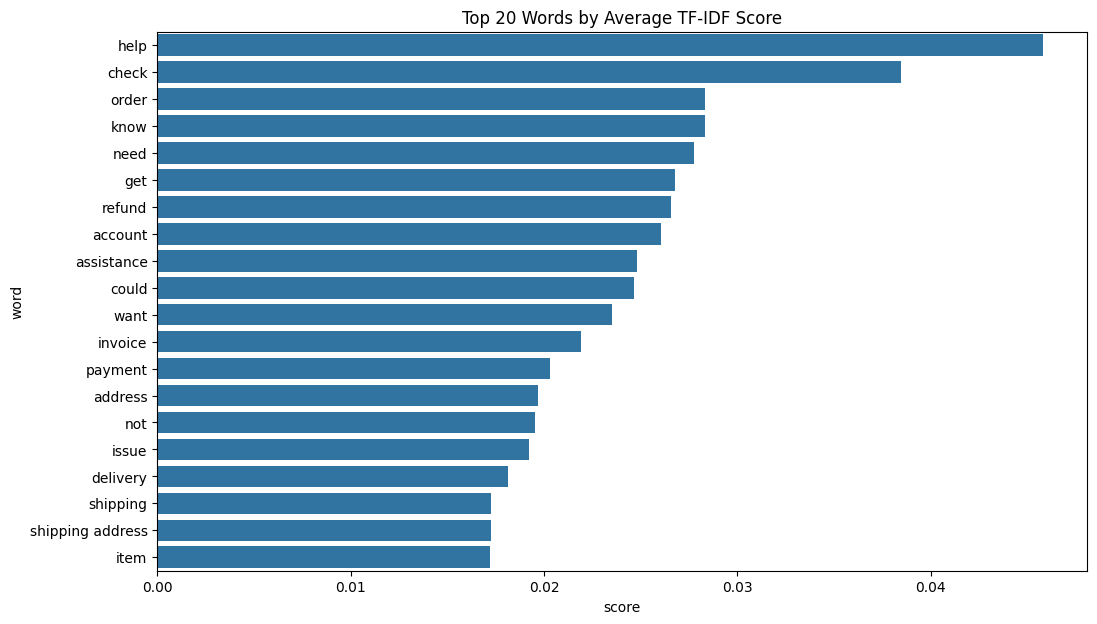

In [14]:
feature_names = (
    tfidf_vectorizer.get_feature_names_out()
)

mean_tfidf = np.asarray(
    X_train_tfidf.mean(axis=0)
).flatten()

tfidf_words = pd.DataFrame({
    "word": feature_names,
    "score": mean_tfidf
})

top_words = tfidf_words.sort_values(
    by="score",
    ascending=False
).head(20)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_words,
    x="score",
    y="word"
)

plt.title("Top 20 Words by Average TF-IDF Score")

plt.show()

In [15]:
print("Training shape:", X_train_tfidf.shape)

print("Testing shape:", X_test_tfidf.shape)

print("Training non-zero values:", X_train_tfidf.nnz)

print("Testing non-zero values:", X_test_tfidf.nnz)

print(
    "Vocabulary size:",
    len(tfidf_vectorizer.get_feature_names_out())
)

Training shape: (6540, 1460)
Testing shape: (1635, 1460)
Training non-zero values: 47951
Testing non-zero values: 12059
Vocabulary size: 1460


In [18]:
import joblib

joblib.dump(
    tfidf_vectorizer,
    "/content/sample_data/tfidf_vectorizer.pkl"
)

print("TF-IDF vectorizer saved successfully!")

TF-IDF vectorizer saved successfully!
